# Leave-one-dataset-out (LODO) classification — all common genes

Plan §6. Each fold trains on all cohorts but one and predicts the left-out cohort; every cohort is
an unseen test set exactly once. There is no separate hold-out set.

- **Input:** `Data/ML_input/all2.xlsx` (1322 samples × 8,314 genes common to all 19 series — 14 microarray
  + 5 RNA-Seq — from `all2.R`; C4BPA is not among them, absent from two RNA-Seq deposits). Features are every gene column plus `Compartment` and
  `Sex` — the same feature set as `train_ML2.ipynb`.
- **No feature selection.** `train_ML2.ipynb` picks genes with importance ≥ 5 from a model fitted on all
  training studies and then cross-validates on them, which leaks the test cohorts into the selection.
  That step is not repeated here; a valid version would have to select inside each fold.
  Expression values are as deposited (uncorrected; three value scales, see CLAUDE.md) — part of what
  LODO tests is whether a model survives that.
- **Outputs:** run 1 (all genes) -> `Results/ML_training/ALL/ALL/`: `ML_ALL_perfs.xlsx` (models and
  performance scores), `ML_ALL_AUC_by_F1.png` and `ML_ALL_AUC_by_AUC.png` (mean ROC of the best model by
  F1 / by ROC-AUC; the dummy is never chosen), `ML_ALL_FEAT_IMP_by_AUC.xlsx` and `ML_ALL_FEAT_IMP_by_F1.xlsx`
  (feature importances of those two models), plus `ML_ALL_sessionInfo.txt`. Run 2 is done twice: on the top N
  genes of run 1's best model by ROC-AUC -> `ALL/TOP_<N>_by_AUC/`, and of its best model by F1 ->
  `ALL/TOP_<N>_by_F1/`; the same files, named `ML_TOP_<N>_by_AUC_*` / `ML_TOP_<N>_by_F1_*`.
- **Switches (first cell):** `FAST = True` runs Logistic Regression only.
  `TOP_FEATURES_FOR_THE_SECOND_RUN` (N): run 1 uses every feature; if N is smaller than the gene count, run 2
  repeats LODO on the N top-ranked genes of run 1's best model (by ROC-AUC, and again by F1) plus `Compartment` and `Sex` (always kept,
  not counted in N), into `ALL/TOP_<N>/`. That ranking comes
  from a model fitted on all cohorts, so run 2 leaks the test cohorts into the selection and is optimistic;
  a valid version would select inside each fold.
- **Groups (17 LODO cohorts):** `StudyID`, each dataset as it is (GSE104948 and GSE104954, the two ERCB
  compartments, are separate cohorts — by instruction, 2026-11-04; they may share biopsies, which GEO cannot
  confirm, so their held-out scores may be optimistic); only GSE108109 +
  GSE200828 + GSE219185 merged into one NEPTUNE cohort (`MERGE_NEPTUNE`): GSE200828 reuses 96 GSE108109
  samples (`Results/SampleOverlap`) and GSE219185 is the tubulointerstitium of NEPTUNE patients whose glomeruli
  are in GSE108109. GSE137570 (24 CKD) is a cohort with no controls: its F1 / precision / recall / accuracy
  are computed, its ROC-AUC is undefined and left out of the mean ROC-AUC and the mean ROC curve.
- **`Platform`** (Microarray / RNA-Seq) is never a feature: it is confounded with study.
- **Models:** all 17 standalone classifiers in PyCaret 3.3.2's model library, with PyCaret's default
  arguments (`random_state=42`). `compare_models()` runs 14 of them by default; RBF SVM, Gaussian
  process and MLP are its `turbo=False` models. XGBoost and CatBoost are not installed. PyCaret's
  meta-estimators (bagging, stacking, voting, calibration) wrap other models and are not included.
- **Preprocessing** mirrors PyCaret's defaults — numeric mean imputation, categorical mode imputation,
  one-hot encoding, no scaling — and sits inside the `Pipeline`, so it is fitted on the training
  cohorts of each fold only. No model is selected on these scores.
- **Metrics:** F1, precision, recall, accuracy and ROC-AUC, each computed on every left-out cohort and
  then averaged (unweighted) over the 17 cohorts — the same convention as PyCaret's `compare_models`,
  which averages over folds. Positive class = Disease; labels from `predict()`, scores from
  `predict_proba()` or, for ridge and linear SVM, `decision_function()`. The report is sorted by ROC-AUC.
- **Why not pool the predictions for ROC-AUC:** each fold's model is trained on a different mix of
  cohorts, so its score level shifts from fold to fold and a pooled ROC mostly ranks those shifts —
  the prior-only dummy would get ROC-AUC ≈ 0.19 instead of 0.5.
- **F1 rewards predicting "Disease":** ~80% of samples are Disease, so the dummy model that always
  predicts it scores a high F1. Compare every model against the dummy row, and read ROC-AUC alongside.

In [11]:
import sys, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import lightgbm
from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, ExtraTreesClassifier, GradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
MERGE_NEPTUNE = True       # GSE108109 + GSE200828 + GSE219185 -> one LODO group (shared NEPTUNE patients)
FAST = False                # True: Logistic Regression only (quick check)
TOP_FEATURES_FOR_THE_SECOND_RUN = 50   # run 2: this many top genes of run 1 + all CATEGORICAL (skipped if >= all genes)

DATA_PATH = Path('../Data/ML_input/all2.xlsx')
OUT_DIR = Path('../Results/ML_training/ALL')
OUT_DIR.mkdir(parents=True, exist_ok=True)

META = ['GSM', 'StudyID', 'Batch', 'Condition', 'Indication', 'Platform']   # identifiers, never features
CATEGORICAL = ['Compartment', 'Sex']
TARGET = 'Disease_Label'

In [12]:
df = pd.read_excel(DATA_PATH)
GENES = [c for c in df.columns if c not in META + CATEGORICAL + [TARGET]]   # as in train_ML2.ipynb
assert all(pd.api.types.is_numeric_dtype(df[g]) for g in GENES)

# NEPTUNE: GSE200828 reuses 96 GSE108109 samples (Results/SampleOverlap); GSE219185 is the tubulointerstitium
# of NEPTUNE patients whose glomeruli are in GSE108109. Held out together, so no patient is on both sides of a fold.
NEPTUNE = {'GSE108109', 'GSE200828', 'GSE219185'}
df['Cohort'] = np.where(MERGE_NEPTUNE & df['StudyID'].isin(NEPTUNE), 'NEPTUNE', df['StudyID'])

X = df[GENES + CATEGORICAL]
y = df[TARGET].to_numpy()
groups = df['Cohort'].to_numpy()

print(df.shape, '| genes:', len(GENES), '| folds:', df['Cohort'].nunique())
pd.crosstab(df['Cohort'], df[TARGET], margins=True)

(850, 10431) | genes: 10422 | folds: 10


Disease_Label,0,1,All
Cohort,,,
ERCB,42,89,131
GSE108109,6,105,111
GSE116626,7,74,81
GSE121233,5,5,10
GSE129973,20,20,40
GSE200828,6,147,153
GSE30122,50,19,69
GSE66494,8,53,61
GSE96804,20,41,61


In [13]:
def make_pipeline(model, genes, categorical):
    # PyCaret defaults: mean / mode imputation, one-hot encoding, no normalisation
    num = [('num', SimpleImputer(strategy='mean'), genes)] if genes else []
    cat = [('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                             ('onehot', OneHotEncoder(handle_unknown='ignore'))]), categorical)] if categorical else []
    return Pipeline([('pre', ColumnTransformer(num + cat)), ('model', clone(model))])

RS = RANDOM_STATE
# PyCaret 3.3.2 model library: ID -> (name, estimator with PyCaret's default args, in compare_models turbo)
PYCARET_MODELS = {
    'lr':       ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=RS), True),
    'knn':      ('K Neighbors Classifier', KNeighborsClassifier(n_jobs=-1), True),
    'nb':       ('Naive Bayes', GaussianNB(), True),
    'dt':       ('Decision Tree Classifier', DecisionTreeClassifier(random_state=RS), True),
    'svm':      ('SVM - Linear Kernel', SGDClassifier(tol=0.001, loss='hinge', penalty='l2', eta0=0.001,
                                                      random_state=RS, n_jobs=-1), True),
    'rbfsvm':   ('SVM - Radial Kernel', SVC(gamma='auto', C=1.0, probability=True, kernel='rbf',
                                            random_state=RS), False),
    'gpc':      ('Gaussian Process Classifier', GaussianProcessClassifier(copy_X_train=False, random_state=RS,
                                                                          n_jobs=-1), False),
    'mlp':      ('MLP Classifier', MLPClassifier(random_state=RS, max_iter=500), False),
    'ridge':    ('Ridge Classifier', RidgeClassifier(random_state=RS), True),
    'rf':       ('Random Forest Classifier', RandomForestClassifier(random_state=RS, n_jobs=-1), True),
    'qda':      ('Quadratic Discriminant Analysis', QuadraticDiscriminantAnalysis(), True),
    'ada':      ('Ada Boost Classifier', AdaBoostClassifier(random_state=RS), True),
    'gbc':      ('Gradient Boosting Classifier', GradientBoostingClassifier(random_state=RS), True),
    'lda':      ('Linear Discriminant Analysis', LinearDiscriminantAnalysis(), True),
    'et':       ('Extra Trees Classifier', ExtraTreesClassifier(random_state=RS, n_jobs=-1), True),
    'lightgbm': ('Light Gradient Boosting Machine', LGBMClassifier(random_state=RS, n_jobs=-1, verbose=-1), True),
    'dummy':    ('Dummy Classifier', DummyClassifier(strategy='prior', random_state=RS), True),
}
if FAST:
    PYCARET_MODELS = {'lr': PYCARET_MODELS['lr']}

In [14]:
def positive_score(pipe, X_test):
    """Score for the Disease class: probability when available, else the decision function."""
    if hasattr(pipe, 'predict_proba'):
        return pipe.predict_proba(X_test)[:, 1]
    return pipe.decision_function(X_test)

def lodo(genes, categorical):
    """LODO: one fold per cohort; every sample gets exactly one out-of-fold prediction per model."""
    X = df[genes + categorical]
    logo = LeaveOneGroupOut()
    oof = []
    with warnings.catch_warnings():
        # expected on these data: QDA collinearity (one-hot columns), SAMME.R deprecation in AdaBoost
        warnings.filterwarnings('ignore', category=UserWarning)
        warnings.filterwarnings('ignore', category=FutureWarning)
        for i, (mid, (name, est, _)) in enumerate(PYCARET_MODELS.items(), 1):
            print(f'[{i}/{len(PYCARET_MODELS)}] Training {name} ({mid})', flush=True)
            pipe = make_pipeline(est, genes, categorical)
            for train_idx, test_idx in logo.split(X, y, groups):
                held_out = np.unique(groups[test_idx])
                assert len(held_out) == 1 and held_out[0] not in set(groups[train_idx])
                pipe.fit(X.iloc[train_idx], y[train_idx])
                X_test = X.iloc[test_idx]
                oof.append(pd.DataFrame({'Model_ID': mid, 'Cohort': held_out[0],
                                         'GSM': df['GSM'].iloc[test_idx].to_numpy(), 'y_true': y[test_idx],
                                         'score': positive_score(pipe, X_test), 'y_pred': pipe.predict(X_test)}))
    oof = pd.concat(oof, ignore_index=True)
    assert (oof.groupby('Model_ID').size() == len(df)).all()
    assert not oof.duplicated(['Model_ID', 'GSM']).any()
    return oof

In [15]:
def metrics(d):
    return {'F1': f1_score(d['y_true'], d['y_pred'], zero_division=0),
            'Precision': precision_score(d['y_true'], d['y_pred'], zero_division=0),
            'Recall': recall_score(d['y_true'], d['y_pred'], zero_division=0),
            'Accuracy': accuracy_score(d['y_true'], d['y_pred']),
            'ROC-AUC': roc_auc_score(d['y_true'], d['score']) if d['y_true'].nunique() == 2 else np.nan}

METRICS = ['F1', 'Precision', 'Recall', 'Accuracy', 'ROC-AUC']

def lodo_metrics(oof):
    per_cohort = pd.DataFrame([{'Model_ID': mid, 'Cohort': c, 'n': len(d),
                                'n_control': int((d['y_true'] == 0).sum()), 'n_disease': int((d['y_true'] == 1).sum()),
                                **metrics(d)}
                               for (mid, c), d in oof.groupby(['Model_ID', 'Cohort'], sort=False)])

    # One value per metric per model: mean over the left-out cohorts (as PyCaret averages over folds)
    means = per_cohort.groupby('Model_ID', sort=False)[METRICS].mean()
    summary = pd.DataFrame({
        'Model': [PYCARET_MODELS[m][0] for m in means.index],
        'PyCaret ID': means.index,
        'In compare_models (turbo)': [PYCARET_MODELS[m][2] for m in means.index],
        **{m: means[m].to_numpy() for m in METRICS}})
    summary = summary.sort_values('ROC-AUC', ascending=False, ignore_index=True, kind='stable')
    return per_cohort, summary

In [16]:
import textwrap

def plot_best_roc(oof, summary, features, out_dir, prefix, by='F1'):
    # Mean ROC curve of the best model by mean `by` (F1 or ROC-AUC; the dummy baseline excluded): the per-cohort
    # curves averaged vertically at fixed false positive rates. Predictions are not pooled across folds - each
    # fold's model has its own score scale.
    ranked = summary[summary['PyCaret ID'] != 'dummy'].sort_values(by, ascending=False, kind='stable')
    best_id = ranked['PyCaret ID'].iloc[0]
    best_f1, best_auc = ranked[['F1', 'ROC-AUC']].iloc[0]
    fpr_grid = np.linspace(0, 1, 201)
    tprs, aucs, skipped = [], [], []
    for cohort, d in oof[oof['Model_ID'] == best_id].groupby('Cohort', sort=False):
        if d['y_true'].nunique() < 2:            # ROC undefined with one class
            skipped.append(cohort)
            continue
        fpr, tpr, _ = roc_curve(d['y_true'], d['score'])
        tpr_grid = np.interp(fpr_grid, fpr, tpr)
        tpr_grid[0] = 0.0
        tprs.append(tpr_grid)
        aucs.append(roc_auc_score(d['y_true'], d['score']))
    tpr_mean = np.mean(tprs, axis=0)
    tpr_mean[-1] = 1.0

    fig, ax = plt.subplots(figsize=(9, 10.5))   # larger canvas for the doubled font sizes
    ax.plot(fpr_grid, tpr_mean, lw=2.5, color='#0000FF',
            label=f'Mean of {len(aucs)} left-out cohorts: AUC {np.mean(aucs):.2f}')
    ax.plot([0, 1], [0, 1], ls='--', lw=1, color='grey', label='Chance')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.01); ax.set_aspect('equal')
    ax.set_xlabel('False positive rate (1 - specificity)', fontsize=20)
    ax.set_ylabel('True positive rate (sensitivity)', fontsize=20)
    ax.tick_params(labelsize=20)
    ax.set_title(f'LODO, {features}\nmean ROC of the best model by {by}:\n'
                 f'{PYCARET_MODELS[best_id][0]} ({best_id})\n'
                 f'mean F1 {best_f1:.3f}, mean ROC-AUC {best_auc:.3f}', fontsize=20)
    ax.legend(fontsize=16, loc='lower right')
    note = 'Average of the per-cohort ROC curves; each cohort scored by the model trained on the others.'
    if skipped:
        note += f' Not included (one class only): {", ".join(skipped)}.'
    fig.text(0.01, 0.005, textwrap.fill(note, 85), fontsize=14, color='grey')
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(out_dir / f"{prefix}_AUC_by_{by.replace('ROC-AUC', 'AUC')}.png", dpi=200)
    plt.show()

In [17]:
# Feature importances of the best model by F1 and by ROC-AUC (dummy excluded, as for the ROC figures), refitted on
# all samples (as PyCaret does after compare_models). These show what the model relies on when trained on every cohort;
# LODO validates the model, not this ranking.
# - Native where the model has them, one row per model input (each one-hot column separately): |coefficient| for
#   linear models (inputs are not scaled, so sizes also follow each gene's value scale; the signed Coefficient is kept,
#   > 0 pushes towards Disease), feature_importances_ for trees / boosting.
# - Otherwise permutation importance: mean drop in ROC-AUC when one input column is shuffled (5 repeats), on the
#   samples the model was fitted on.
NATIVE_IMPORTANCE = ['lr', 'svm', 'ridge', 'lda', 'dt', 'rf', 'et', 'ada', 'gbc', 'lightgbm']

def best_model_importances(summary, genes, categorical, by):
    ranked = summary[summary['PyCaret ID'] != 'dummy'].sort_values(by, ascending=False, kind='stable')
    best_id = ranked['PyCaret ID'].iloc[0]
    X_all = df[genes + categorical]
    pipe = make_pipeline(PYCARET_MODELS[best_id][1], genes, categorical).fit(X_all, y)
    model = pipe.named_steps['model']
    if best_id in NATIVE_IMPORTANCE:
        kind, features = zip(*(name.split('__', 1) for name in pipe.named_steps['pre'].get_feature_names_out()))
        # Source = the input column a feature comes from (a one-hot column maps back to Compartment / Sex)
        source = [f if k == 'num' else next(c for c in categorical if f.startswith(c + '_'))
                  for k, f in zip(kind, features)]
        if hasattr(model, 'coef_'):
            coef = np.ravel(model.coef_)
            imp = pd.DataFrame({'Feature': features, 'Source': source, 'Importance': np.abs(coef), 'Coefficient': coef})
            method = '|coefficient|'
        else:
            imp = pd.DataFrame({'Feature': features, 'Source': source, 'Importance': model.feature_importances_})
            method = 'feature_importances_'
    else:
        with warnings.catch_warnings():
            warnings.filterwarnings('ignore', category=UserWarning)
            perm = permutation_importance(pipe, X_all, y, scoring='roc_auc', n_repeats=5,
                                          random_state=RANDOM_STATE, n_jobs=-1)
        imp = pd.DataFrame({'Feature': genes + categorical, 'Source': genes + categorical,
                            'Importance': perm.importances_mean})
        method = 'permutation (mean ROC-AUC drop)'
    imp = imp.sort_values('Importance', ascending=False, ignore_index=True, kind='stable')
    imp.insert(0, 'Rank', np.arange(1, len(imp) + 1))
    head = {'Selected by': by, 'Model': PYCARET_MODELS[best_id][0], 'PyCaret ID': best_id, 'Importance method': method}
    return pd.concat([pd.DataFrame(head, index=imp.index), imp], axis=1)

def report_importances(summary, genes, categorical, out_dir, prefix, n_print=None):
    """Print the importances of the best model by F1 and by ROC-AUC; one file each, <prefix>_FEAT_IMP_by_F1.xlsx /
    _by_AUC.xlsx. Returns {by: importances}."""
    out = {}
    for by in ['F1', 'ROC-AUC']:
        imp = out[by] = best_model_importances(summary, genes, categorical, by)
        imp[[c for c in ['Source', 'Importance', 'Coefficient'] if c in imp]].to_excel(
            out_dir / f"{prefix}_FEAT_IMP_by_{by.replace('ROC-AUC', 'AUC')}.xlsx", index=False)
        first = imp.iloc[0]
        shown = imp if n_print is None else imp.head(n_print)
        print(f"\n=== Best model by {by}: {first['Model']} ({first['PyCaret ID']}); importance = {first['Importance method']}"
              + ('' if n_print is None or n_print >= len(imp) else f'; top {n_print:,} of {len(imp):,} shown') + ' ===')
        cols = ['Rank', 'Feature', 'Importance'] + (['Coefficient'] if 'Coefficient' in imp else [])
        print(shown[cols].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
    return out


In [18]:
def write_session_info(out_dir, prefix, genes, categorical, note=''):
    # Provenance next to the outputs (project convention): versions, settings, models, input
    with open(out_dir / f'{prefix}_sessionInfo.txt', 'w') as fh:
        fh.write(f'python {sys.version}\nplatform {platform.platform()}\n')
        fh.write(f'scikit-learn {sklearn.__version__}\nlightgbm {lightgbm.__version__}\n'
                 f'pandas {pd.__version__}\nnumpy {np.__version__}\n')
        fh.write(f'RANDOM_STATE={RANDOM_STATE} MERGE_NEPTUNE={MERGE_NEPTUNE} FAST={FAST} TOP_FEATURES_FOR_THE_SECOND_RUN={TOP_FEATURES_FOR_THE_SECOND_RUN}\n')
        fh.write(f'models (PyCaret 3.3.2 defaults): {", ".join(PYCARET_MODELS)}\n')
        fh.write(f'input {DATA_PATH.resolve()} ({len(df)} samples, {len(genes)} genes + {categorical}, '
                 f'{df["Cohort"].nunique()} LODO groups)\n')
        if note:
            fh.write(note + '\n')

=== Run 1: LODO on all features ===
[1/17] Training Logistic Regression (lr)
[2/17] Training K Neighbors Classifier (knn)
[3/17] Training Naive Bayes (nb)
[4/17] Training Decision Tree Classifier (dt)
[5/17] Training SVM - Linear Kernel (svm)
[6/17] Training SVM - Radial Kernel (rbfsvm)
[7/17] Training Gaussian Process Classifier (gpc)
[8/17] Training MLP Classifier (mlp)
[9/17] Training Ridge Classifier (ridge)
[10/17] Training Random Forest Classifier (rf)
[11/17] Training Quadratic Discriminant Analysis (qda)
[12/17] Training Ada Boost Classifier (ada)
[13/17] Training Gradient Boosting Classifier (gbc)
[14/17] Training Linear Discriminant Analysis (lda)
[15/17] Training Extra Trees Classifier (et)
[16/17] Training Light Gradient Boosting Machine (lightgbm)
[17/17] Training Dummy Classifier (dummy)


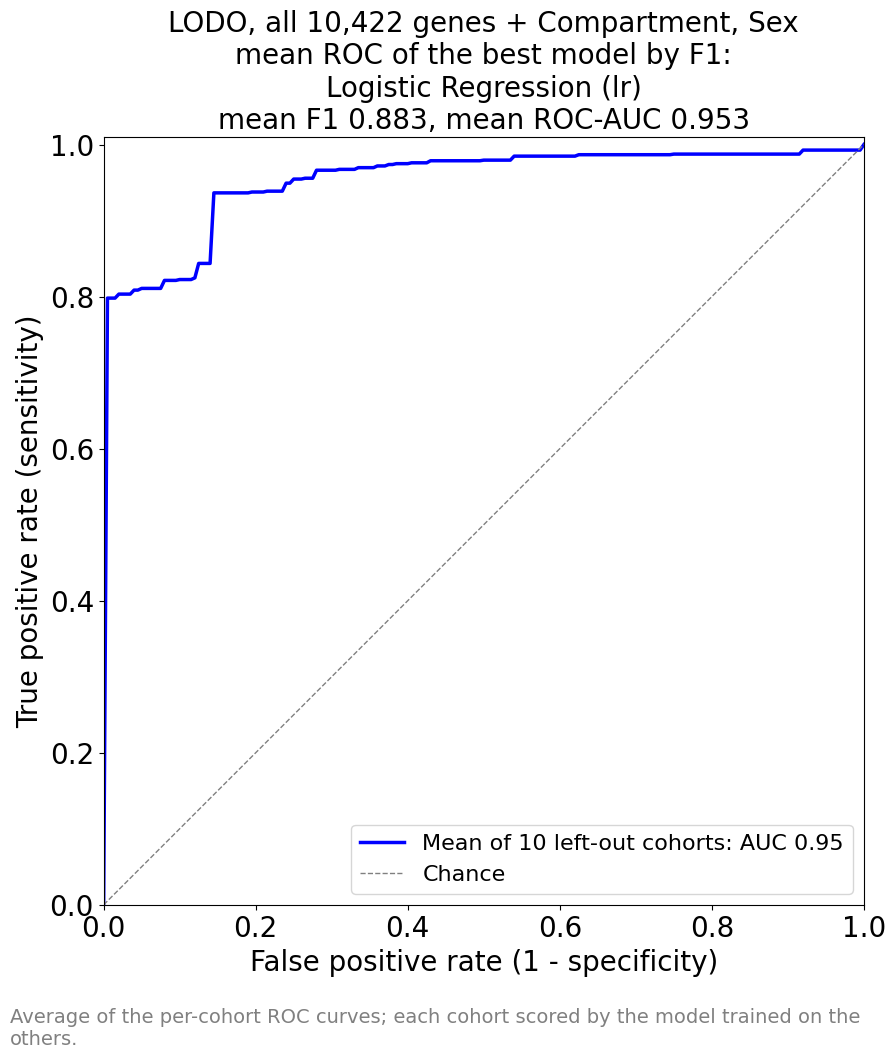

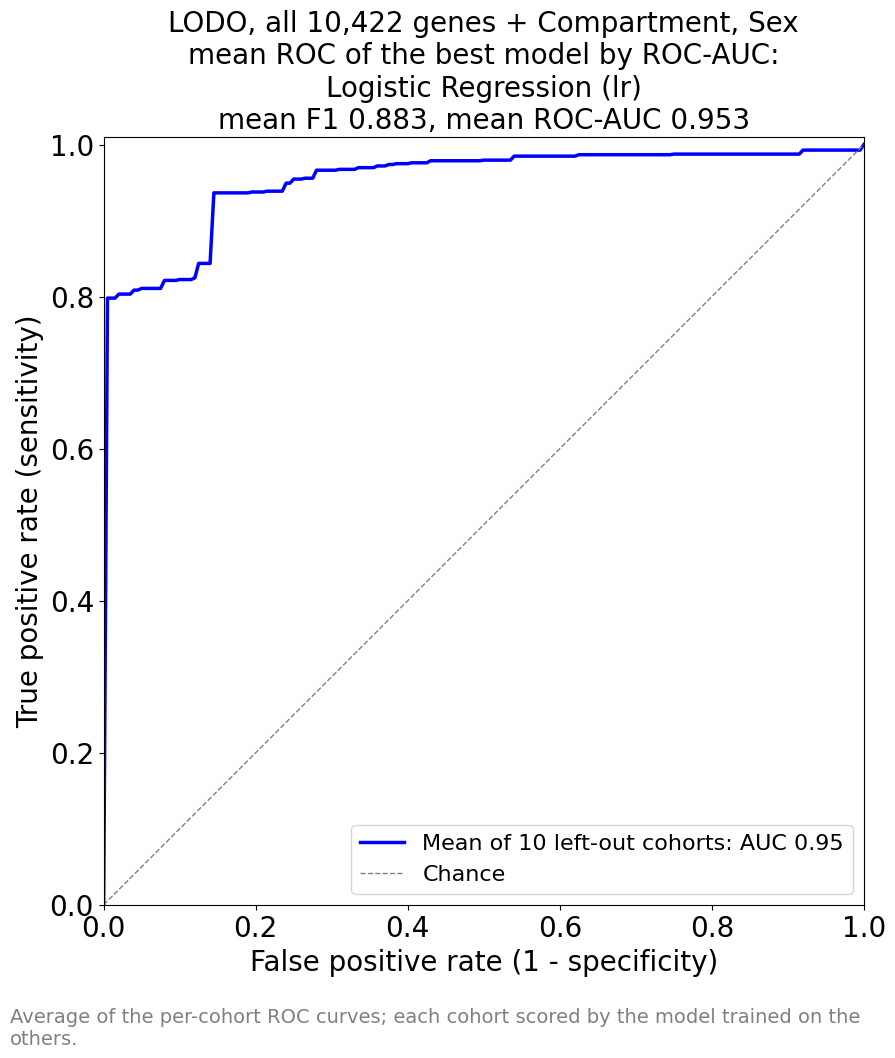

                          Model PyCaret ID    F1  Precision  Recall  Accuracy  ROC-AUC
            Logistic Regression         lr 0.883      0.884   0.923     0.858    0.953
            SVM - Linear Kernel        svm 0.880      0.890   0.903     0.861    0.953
               Ridge Classifier      ridge 0.836      0.885   0.890     0.801    0.939
   Linear Discriminant Analysis        lda 0.813      0.878   0.876     0.777    0.917
   Gradient Boosting Classifier        gbc 0.787      0.806   0.893     0.721    0.866
       Random Forest Classifier         rf 0.743      0.754   0.880     0.671    0.858
Light Gradient Boosting Machine   lightgbm 0.802      0.812   0.913     0.750    0.857
                 MLP Classifier        mlp 0.697      0.759   0.803     0.635    0.851
         Extra Trees Classifier         et 0.793      0.751   0.942     0.703    0.826
           Ada Boost Classifier        ada 0.828      0.817   0.904     0.768    0.817
            SVM - Radial Kernel     rbfsvm 

In [19]:
def run(genes, categorical, out_dir, prefix, features, note=''):
    """LODO over the PyCaret models (FAST: lr only): <prefix>_perfs.xlsx, the two ROC figures,
    <prefix>_FEAT_IMP_by_AUC.xlsx / _by_F1.xlsx and provenance in out_dir."""
    out_dir.mkdir(parents=True, exist_ok=True)
    oof = lodo(genes, categorical)
    per_cohort, summary = lodo_metrics(oof)
    for by in ['F1', 'ROC-AUC']:
        plot_best_roc(oof, summary, features, out_dir, prefix, by)
    # LODO performance per classifier (mean over the left-out cohorts), sorted by ROC-AUC; the printed table also as .xlsx
    perfs = summary[['Model', 'PyCaret ID'] + METRICS].round(3)
    perfs.to_excel(out_dir / f'{prefix}_perfs.xlsx', index=False)
    print(perfs.to_string(index=False))
    importances = report_importances(summary, genes, categorical, out_dir, prefix, n_print=50)   # full list in the .xlsx
    write_session_info(out_dir, prefix, genes, categorical, note)
    return summary, per_cohort, importances

# Run 1: every feature
print('=== Run 1: LODO on all features ===')
summary, per_cohort, importances = run(GENES, CATEGORICAL, OUT_DIR / 'ALL', 'ML_ALL',
                                     f"all {len(GENES):,} genes + {', '.join(CATEGORICAL)}")


=== Run 2 (TOP_50_by_AUC): LODO on the top 50 of 10,422 genes of Logistic Regression (best by ROC-AUC) + ['Compartment', 'Sex'] ===
[1/17] Training Logistic Regression (lr)
[2/17] Training K Neighbors Classifier (knn)
[3/17] Training Naive Bayes (nb)
[4/17] Training Decision Tree Classifier (dt)
[5/17] Training SVM - Linear Kernel (svm)
[6/17] Training SVM - Radial Kernel (rbfsvm)
[7/17] Training Gaussian Process Classifier (gpc)
[8/17] Training MLP Classifier (mlp)
[9/17] Training Ridge Classifier (ridge)
[10/17] Training Random Forest Classifier (rf)
[11/17] Training Quadratic Discriminant Analysis (qda)
[12/17] Training Ada Boost Classifier (ada)
[13/17] Training Gradient Boosting Classifier (gbc)
[14/17] Training Linear Discriminant Analysis (lda)
[15/17] Training Extra Trees Classifier (et)
[16/17] Training Light Gradient Boosting Machine (lightgbm)
[17/17] Training Dummy Classifier (dummy)


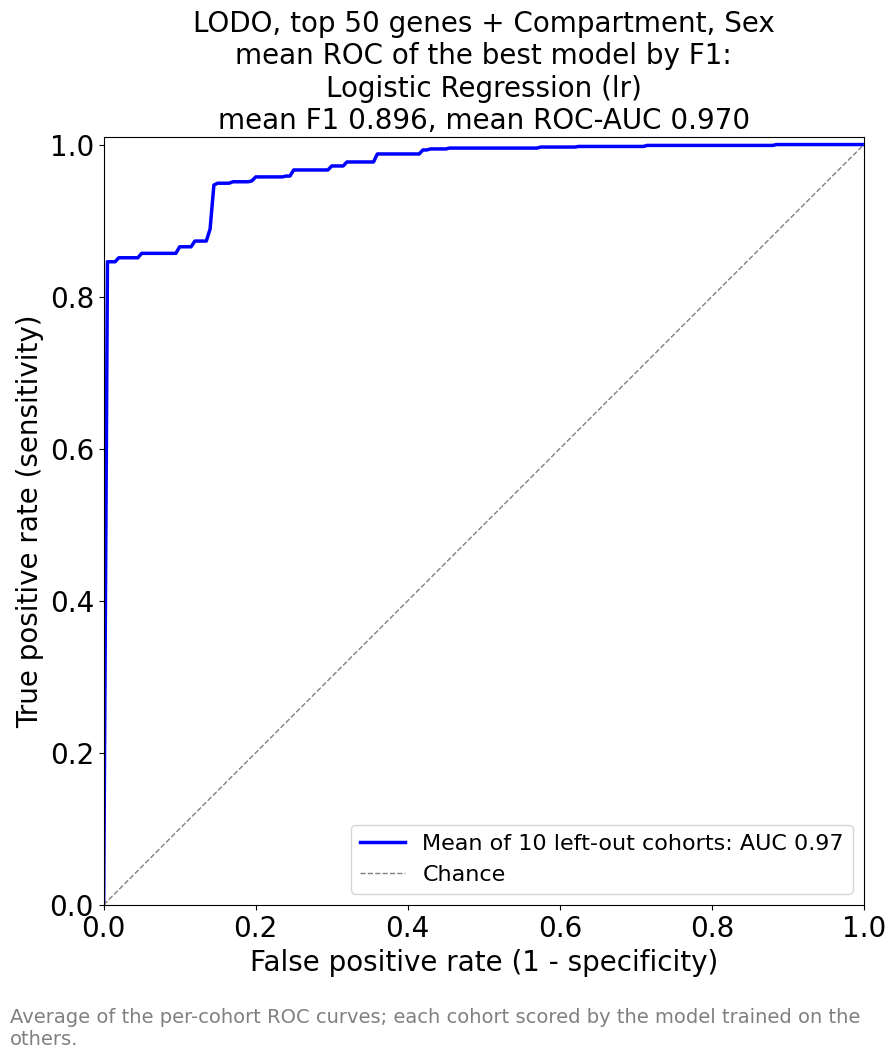

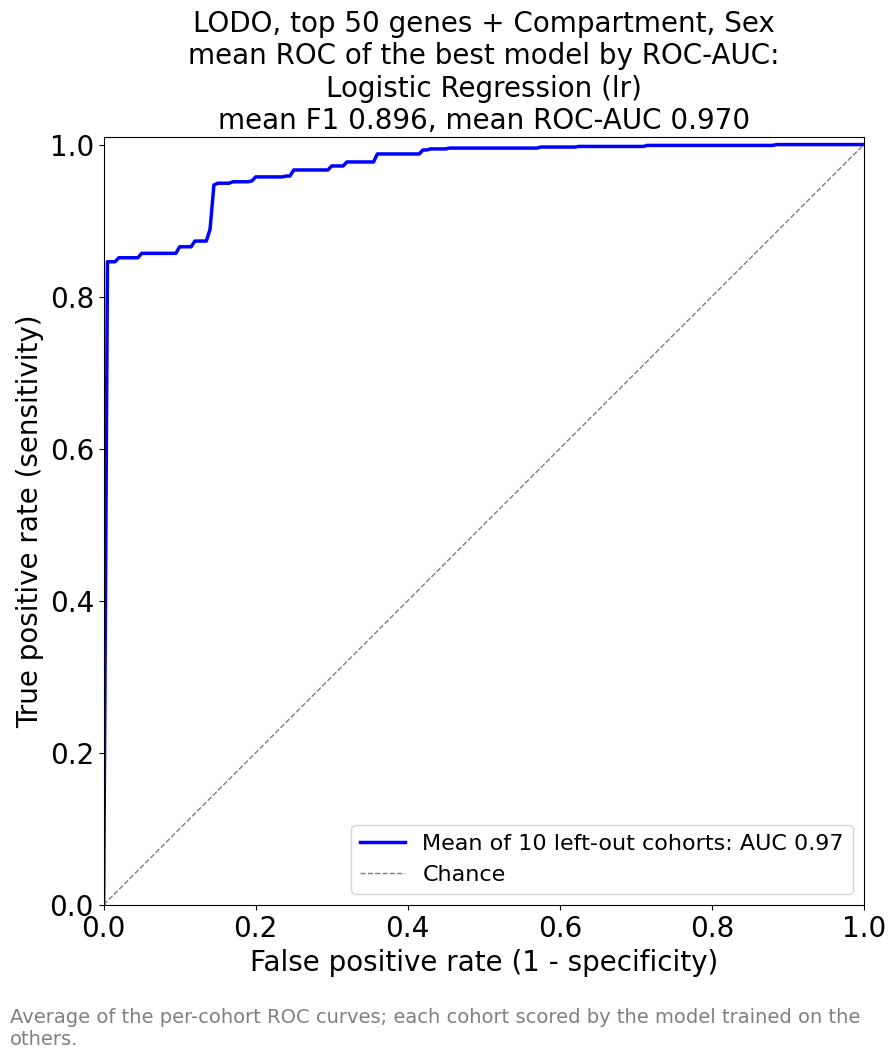

                          Model PyCaret ID    F1  Precision  Recall  Accuracy  ROC-AUC
            Logistic Regression         lr 0.896      0.896   0.942     0.861    0.970
            SVM - Linear Kernel        svm 0.853      0.822   0.945     0.804    0.969
               Ridge Classifier      ridge 0.853      0.885   0.895     0.815    0.959
   Linear Discriminant Analysis        lda 0.847      0.888   0.886     0.811    0.957
                 MLP Classifier        mlp 0.891      0.895   0.936     0.857    0.944
         Extra Trees Classifier         et 0.782      0.817   0.897     0.733    0.884
            SVM - Radial Kernel     rbfsvm 0.836      0.797   0.952     0.768    0.869
   Gradient Boosting Classifier        gbc 0.780      0.803   0.901     0.724    0.869
Light Gradient Boosting Machine   lightgbm 0.824      0.822   0.923     0.770    0.861
           Ada Boost Classifier        ada 0.799      0.834   0.888     0.757    0.857
       Random Forest Classifier         rf 

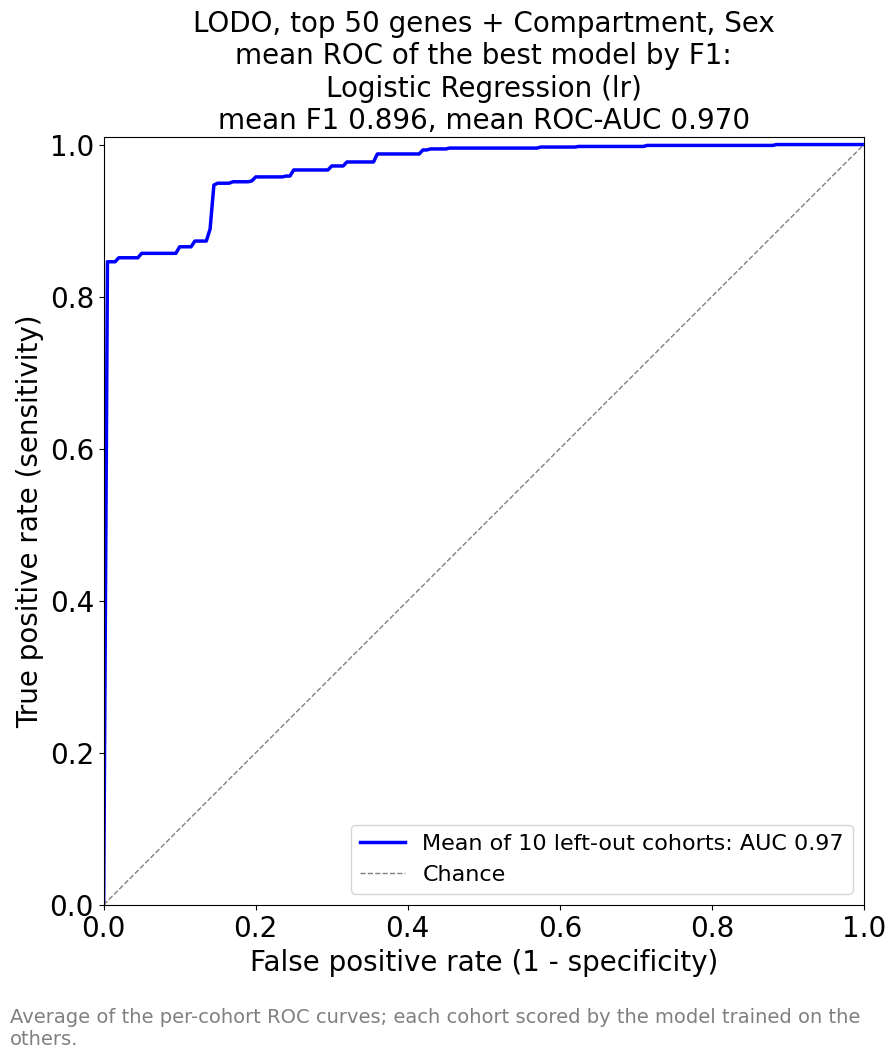

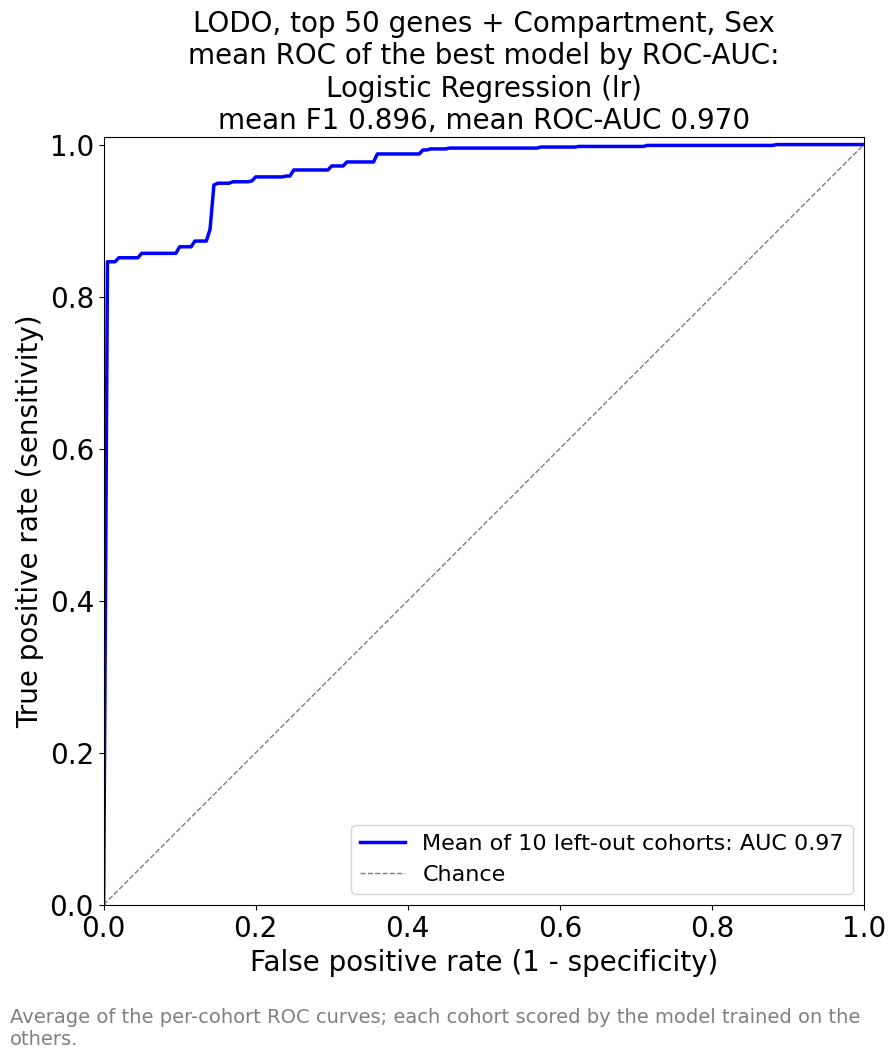

                          Model PyCaret ID    F1  Precision  Recall  Accuracy  ROC-AUC
            Logistic Regression         lr 0.896      0.896   0.942     0.861    0.970
            SVM - Linear Kernel        svm 0.853      0.822   0.945     0.804    0.969
               Ridge Classifier      ridge 0.853      0.885   0.895     0.815    0.959
   Linear Discriminant Analysis        lda 0.847      0.888   0.886     0.811    0.957
                 MLP Classifier        mlp 0.891      0.895   0.936     0.857    0.944
         Extra Trees Classifier         et 0.782      0.817   0.897     0.733    0.884
            SVM - Radial Kernel     rbfsvm 0.836      0.797   0.952     0.768    0.869
   Gradient Boosting Classifier        gbc 0.780      0.803   0.901     0.724    0.869
Light Gradient Boosting Machine   lightgbm 0.824      0.822   0.923     0.770    0.861
           Ada Boost Classifier        ada 0.799      0.834   0.888     0.757    0.857
       Random Forest Classifier         rf 

In [20]:
# Run 2, twice: the TOP_FEATURES_FOR_THE_SECOND_RUN genes ranked highest by run 1's best model by ROC-AUC, and by its best model by F1
# (decreasing importance), plus every CATEGORICAL column (Compartment, Sex) regardless of rank, then the same LODO over
# the same models (FAST switch). If both criteria pick the same model, the two runs use the same genes.
# Optimistic: the ranking comes from a model fitted on ALL cohorts, so every left-out cohort helped pick the
# features it is then tested on. Compare with run 1; do not report it as validated performance.
gene_set = set(GENES)
for by in ['ROC-AUC', 'F1']:
    tag = f"TOP_{TOP_FEATURES_FOR_THE_SECOND_RUN}_by_{by.replace('ROC-AUC', 'AUC')}"
    imp = importances[by]
    ranking = imp.groupby('Source', sort=False)['Importance'].max().sort_values(ascending=False, kind='stable')
    gene_ranking = [f for f in ranking.index if f in gene_set]   # genes only, decreasing importance
    if TOP_FEATURES_FOR_THE_SECOND_RUN >= len(gene_ranking):
        print(f'Run 2 skipped: TOP_FEATURES_FOR_THE_SECOND_RUN = {TOP_FEATURES_FOR_THE_SECOND_RUN:,} >= {len(gene_ranking):,} genes')
        break
    ranked_genes = gene_ranking[:TOP_FEATURES_FOR_THE_SECOND_RUN]
    top_genes = [g for g in GENES if g in set(ranked_genes)]   # input column order
    top_categorical = CATEGORICAL                              # always included, not counted in N
    assert len(top_genes) == TOP_FEATURES_FOR_THE_SECOND_RUN
    best = imp.iloc[0]
    note = (f'feature selection: top {TOP_FEATURES_FOR_THE_SECOND_RUN} genes by importance of run 1\'s best model by {by} '
            f'({best["Model"]}, fitted on all cohorts), plus all categorical columns; '
            'selection saw the left-out cohorts, so these LODO scores are optimistic')
    print(f'\n=== Run 2 ({tag}): LODO on the top {TOP_FEATURES_FOR_THE_SECOND_RUN:,} of {len(gene_ranking):,} genes of '
          f'{best["Model"]} (best by {by}) + {top_categorical} ===')
    summary_top, per_cohort_top, _ = run(top_genes, top_categorical, OUT_DIR / tag, f'ML_{tag}',
                                     f"top {len(top_genes):,} genes + {', '.join(top_categorical)}", note)

    # Run 1 vs run 2, per model (mean over the left-out cohorts)
    comparison = summary[['Model', 'PyCaret ID'] + METRICS].merge(
        summary_top[['PyCaret ID'] + METRICS], on='PyCaret ID', suffixes=(' all', f' {tag}'))
    for m in METRICS:
        comparison[f'{m} change'] = comparison[f'{m} {tag}'] - comparison[f'{m} all']
    print(f'\n=== All {len(gene_ranking):,} genes vs {tag} (both + {CATEGORICAL}; run 2 optimistic, see above) ===')
    print(comparison[['Model', 'PyCaret ID', 'ROC-AUC all', f'ROC-AUC {tag}', 'ROC-AUC change',
                      'F1 all', f'F1 {tag}', 'F1 change']]
          .round(3).to_string(index=False))
